Total de ofertas: 1317
Ofertas con descripción: 553


,Cantidad,Porcentaje
seniority,,
No especificado,302,54.61
Lead / Manager,126,22.78
Senior,112,20.25
Trainee,7,1.27
Semi Senior,5,0.90
Junior,1,0.18


,Cantidad,Porcentaje
experiencia_estimada,,
5 años o más,126,22.78
4 a 6 años,112,20.25
Menos de 1 año,7,1.27
2 a 4 años,5,0.90
1 a 2 años,1,0.18


,Cantidad,Porcentaje
tipo_experiencia,,
No especificado,302,54.61
Experiencia estimada por seniority,251,45.39


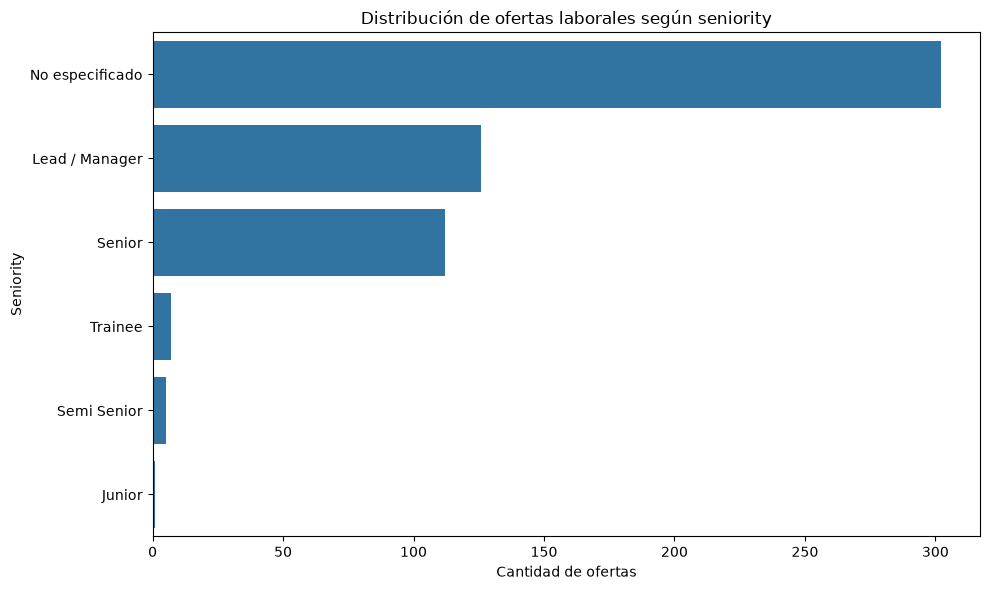

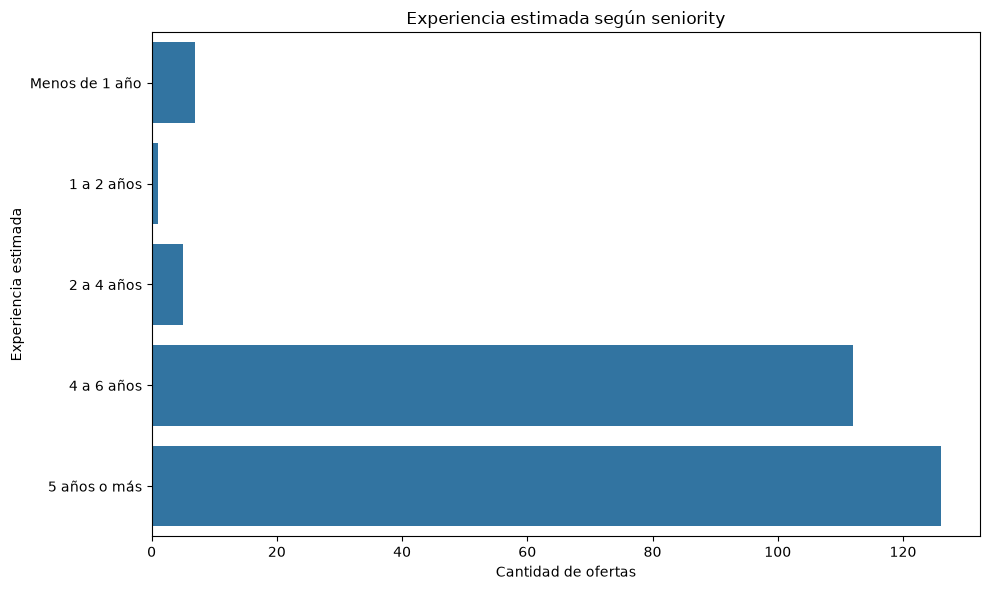

,title,companyName,countryCode,seniority,años_experiencia,experiencia_estimada,tipo_experiencia
764,staff software engineer - mexico,Nubank,MX,No especificado,NaN,NaN,No especificado
765,lead software engineer - mexico city,Nubank,MX,Lead / Manager,NaN,5 años o más,Experiencia estimada por seniority
766,senior software engineer - br,Nubank,BR,Senior,NaN,4 a 6 años,Experiencia estimada por seniority
767,"senior software engineer – mexico city, mexico...",Nubank,MX,Senior,NaN,4 a 6 años,Experiencia estimada por seniority
768,senior business analyst,Nubank,MX,Senior,NaN,4 a 6 años,Experiencia estimada por seniority
769,lead business analyst,Nubank,BR,Lead / Manager,NaN,5 años o más,Experiencia estimada por seniority
770,pessoa engenheira de software sênior - exclusi...,Nubank,BR,Senior,NaN,4 a 6 años,Experiencia estimada por seniority
771,principal product designer,Nubank,CO,No especificado,NaN,NaN,No especificado
772,customer excellence senior analyst - bogotá (b...,Nubank,CO,Senior,NaN,4 a 6 años,Experiencia estimada por seniority
773,enterprise risk management specialist,Nubank,BR,No especificado,NaN,NaN,No especificado


In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns



# 1. CARGA Y PREPARACIÓN DE LOS DATOS


df = pd.read_csv("../data/raw/ofertas_laborales.csv")

df_requisitos = df[
    df["description"].notna() &
    (df["description"].str.strip() != "")
].copy()

df_requisitos["title"] = (
    df_requisitos["title"]
    .fillna("")
    .str.lower()
    .str.strip()
)

df_requisitos["description"] = (
    df_requisitos["description"]
    .fillna("")
    .str.lower()
    .str.strip()
)

df_requisitos["texto_completo"] = (
    df_requisitos["title"] + " " +
    df_requisitos["description"]
)

print("Total de ofertas:", len(df))
print("Ofertas con descripción:", len(df_requisitos))



# 2. CLASIFICACIÓN DE SENIORITY


patrones_seniority = {
    "Trainee": r"\btrainee\b|\bintern(ship)?\b|\bestagi[aá]rio\b|\baprendiz\b",
    "Junior": r"\bjunior\b|\bjr\b|\bj[uú]nior\b",
    "Semi Senior": r"\bsemi[\s-]?senior\b|\bpleno\b|\bssr\b|\bmid[\s-]?level\b|\bmid[\s-]?senior\b",
    "Senior": r"\bsenior\b|\bsr\b|\bs[eê]nior\b",
    "Lead / Manager": r"\blead\b|\bmanager\b|\bl[ií]der\b|\bcoordenador\b|\bgerente\b"
}


def clasificar_seniority(texto):
    for nivel, patron in patrones_seniority.items():
        if re.search(patron, texto):
            return nivel

    return "No especificado"


df_requisitos["seniority"] = (
    df_requisitos["texto_completo"]
    .apply(clasificar_seniority)
)



# 3. EXTRACCIÓN DE AÑOS DE EXPERIENCIA EXPLÍCITOS


patrones_experiencia = [
    r"\b(\d{1,2})\s*\+?\s*(?:years?|yrs?)\b",
    r"\b(\d{1,2})\s*\+?\s*años?\b",
    r"\b(\d{1,2})\s*\+?\s*anos?\b"
]


def extraer_experiencia(texto):
    coincidencias = []

    for patron in patrones_experiencia:
        resultados = re.findall(patron, texto)
        coincidencias.extend(resultados)

    if coincidencias:
        return max(map(int, coincidencias))

    return np.nan


df_requisitos["años_experiencia"] = (
    df_requisitos["texto_completo"]
    .apply(extraer_experiencia)
)



# 4. ESTIMACIÓN DE EXPERIENCIA SEGÚN SENIORITY


equivalencias_experiencia = {
    "Trainee": "Menos de 1 año",
    "Junior": "1 a 2 años",
    "Semi Senior": "2 a 4 años",
    "Senior": "4 a 6 años",
    "Lead / Manager": "5 años o más"
}


df_requisitos["experiencia_estimada"] = (
    df_requisitos["seniority"]
    .map(equivalencias_experiencia)
)



# 5. COMBINAR EXPERIENCIA EXPLÍCITA Y ESTIMADA


def obtener_experiencia_final(fila):
    if pd.notna(fila["años_experiencia"]):
        return "Experiencia explícita"

    if pd.notna(fila["experiencia_estimada"]):
        return "Experiencia estimada por seniority"

    return "No especificado"


df_requisitos["tipo_experiencia"] = (
    df_requisitos
    .apply(obtener_experiencia_final, axis=1)
)



# 6. FRECUENCIA DE SENIORITY


frecuencia_seniority = (
    df_requisitos["seniority"]
    .value_counts()
    .to_frame("Cantidad")
)

frecuencia_seniority["Porcentaje"] = (
    frecuencia_seniority["Cantidad"] /
    len(df_requisitos) * 100
).round(2)

display(frecuencia_seniority)



# 7. FRECUENCIA DE EXPERIENCIA ESTIMADA


frecuencia_experiencia = (
    df_requisitos["experiencia_estimada"]
    .value_counts()
    .to_frame("Cantidad")
)

frecuencia_experiencia["Porcentaje"] = (
    frecuencia_experiencia["Cantidad"] /
    len(df_requisitos) * 100
).round(2)

display(frecuencia_experiencia)



# 8. COMPARACIÓN DE EXPERIENCIA EXPLÍCITA Y ESTIMADA


frecuencia_tipo = (
    df_requisitos["tipo_experiencia"]
    .value_counts()
    .to_frame("Cantidad")
)

frecuencia_tipo["Porcentaje"] = (
    frecuencia_tipo["Cantidad"] /
    len(df_requisitos) * 100
).round(2)

display(frecuencia_tipo)



# 9. GRÁFICO DE SENIORITY


plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_requisitos,
    y="seniority",
    order=df_requisitos["seniority"].value_counts().index
)

plt.title("Distribución de ofertas laborales según seniority")
plt.xlabel("Cantidad de ofertas")
plt.ylabel("Seniority")

plt.tight_layout()
plt.show()



# 10. GRÁFICO DE EXPERIENCIA ESTIMADA


plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_requisitos.dropna(subset=["experiencia_estimada"]),
    y="experiencia_estimada",
    order=[
        "Menos de 1 año",
        "1 a 2 años",
        "2 a 4 años",
        "4 a 6 años",
        "5 años o más"
    ]
)

plt.title("Experiencia estimada según seniority")
plt.xlabel("Cantidad de ofertas")
plt.ylabel("Experiencia estimada")

plt.tight_layout()
plt.show()



# 11. TABLA FINAL


display(
    df_requisitos[
        [
            "title",
            "companyName",
            "countryCode",
            "seniority",
            "años_experiencia",
            "experiencia_estimada",
            "tipo_experiencia"
        ]
    ].head(30)
)


Perfil del profesional buscado
Cliente: TalentHub | Consulting Challenge
Objetivo
Analizar qué características del profesional IT buscan las empresas en sus ofertas laborales: seniority, experiencia, formación académica, certificaciones, idiomas y habilidades blandas.

Preguntas de análisis
1. ¿Qué niveles de seniority aparecen con mayor frecuencia?
2. ¿Cuántos años de experiencia solicitan las ofertas?
3. ¿Qué formación académica se requiere?
4. ¿Qué idiomas y niveles se mencionan?
5. ¿Qué habilidades blandas son más frecuentes?
